In [1]:
import sys
print(sys.executable)

import pandas, sklearn, xgboost
print("Librerías OK")

/home/saurin/sistema-servicios-ia/backend/venv/bin/python
Librerías OK


In [1]:
import pandas as pd

df = pd.read_csv("../data/ordenes.csv")

print("Filas y columnas:", df.shape)
df.head()

Filas y columnas: (4000, 16)


,orden_id,tipo_equipo,marca,modelo,tecnico,especialidad_tecnico,anios_experiencia,descripcion_falla,categoria_falla,prioridad,repuestos,num_repuestos,fecha_ingreso,estado,tiempo_real_dias,costo_real
0,1,laptop,Lenovo,Legion 5,Jorge Ramírez,software,5,no me abre el office ni el navegador,software,baja,NaN,0,2026-04-11 02:28,entregado,1.5,45.86
1,2,laptop,Apple,MacBook Pro 13,Miguel Salazar,hardware,1,la laptop se apaga sola cuando la desconecto,bateria,media,Batería de laptop,1,2025-10-16 04:35,entregado,2.8,268.38
2,3,pc,Lenovo,ThinkCentre M70,Miguel Salazar,hardware,1,dice que no encueentra el sistema operativo,disco_duro,alta,Disco duro HDD,1,2025-08-13 23:25,entregado,5.0,190.17
3,4,laptop,Acer,Nitro 5,Lucía Torres,hardware,3,"hola, perdi mis archivos y no abre carpetas",disco_duro,alta,Disco duro HDD,1,2025-07-01 05:33,entregado,3.7,155.95
4,5,impresora,Canon,Pixma G3110,Rosa Paredes,impresoras,2,"oiga, dice atasco de papel pero no veo nada at...",atasco_papel,media,Rodillo de arrastre,1,2025-06-12 09:36,entregado,1.7,65.83


In [2]:
terminadas = df.dropna(subset=["tiempo_real_dias", "costo_real"]).copy()

print("Ordenes totales:", len(df))
print("Ordenes terminadas (usables para entrenar):", len(terminadas))

terminadas[["tiempo_real_dias", "costo_real"]].describe()

Ordenes totales: 4000
Ordenes terminadas (usables para entrenar): 3984


,tiempo_real_dias,costo_real
count,3984.000000,3984.000000
mean,3.174398,202.627096
std,2.452567,164.151138
min,0.600000,32.820000
25%,1.700000,66.227500
50%,2.400000,162.515000
75%,3.800000,296.472500
max,28.900000,1519.230000


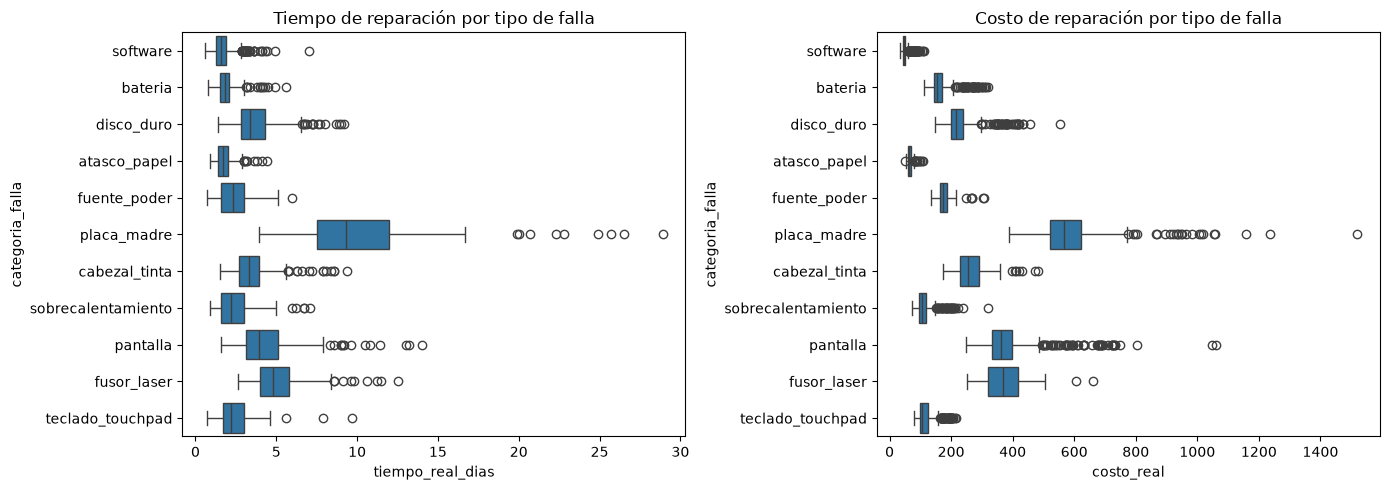

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=terminadas, x="tiempo_real_dias", y="categoria_falla", ax=ax[0])
ax[0].set_title("Tiempo de reparación por tipo de falla")

sns.boxplot(data=terminadas, x="costo_real", y="categoria_falla", ax=ax[1])
ax[1].set_title("Costo de reparación por tipo de falla")

plt.tight_layout()
plt.show()

In [4]:
from sklearn.model_selection import train_test_split

columnas_entrada = ["tipo_equipo", "marca", "categoria_falla", "tecnico",
                    "anios_experiencia", "num_repuestos", "prioridad"]

X = terminadas[columnas_entrada]
y_tiempo = terminadas["tiempo_real_dias"]
y_costo = terminadas["costo_real"]

X_train, X_test, yt_train, yt_test, yc_train, yc_test = train_test_split(
    X, y_tiempo, y_costo, test_size=0.2, random_state=42
)

print("Entrenamiento:", len(X_train), "| Prueba:", len(X_test))

Entrenamiento: 3187 | Prueba: 797


In [5]:
from sklearn.metrics import mean_absolute_error, r2_score

prom_tiempo = yt_train.groupby(X_train["categoria_falla"]).mean()
prom_costo = yc_train.groupby(X_train["categoria_falla"]).mean()

pred_t = X_test["categoria_falla"].map(prom_tiempo)
pred_c = X_test["categoria_falla"].map(prom_costo)

print("LÍNEA BASE (promedio por falla)")
print(f"Tiempo -> MAE: {mean_absolute_error(yt_test, pred_t):.2f} días | R²: {r2_score(yt_test, pred_t):.3f}")
print(f"Costo  -> MAE: {mean_absolute_error(yc_test, pred_c):.2f} soles | R²: {r2_score(yc_test, pred_c):.3f}")

LÍNEA BASE (promedio por falla)
Tiempo -> MAE: 0.82 días | R²: 0.692
Costo  -> MAE: 29.54 soles | R²: 0.890


In [6]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

categoricas = ["tipo_equipo", "marca", "categoria_falla", "tecnico", "prioridad"]
numericas = ["anios_experiencia", "num_repuestos"]

preproceso = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), categoricas),
    ("num", "passthrough", numericas),
])

def crear_modelo(algoritmo):
    return Pipeline([("prep", preproceso), ("modelo", algoritmo)])

algoritmos = {
    "Random Forest": lambda: RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1),
    "XGBoost": lambda: XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=5, random_state=42),
}

resultados = {}
modelos_tiempo, modelos_costo = {}, {}

for nombre, fabrica in algoritmos.items():
    m_t = crear_modelo(fabrica()).fit(X_train, yt_train)
    m_c = crear_modelo(fabrica()).fit(X_train, yc_train)
    modelos_tiempo[nombre], modelos_costo[nombre] = m_t, m_c

    pt, pc = m_t.predict(X_test), m_c.predict(X_test)
    resultados[nombre] = {
        "Tiempo MAE": mean_absolute_error(yt_test, pt), "Tiempo R²": r2_score(yt_test, pt),
        "Costo MAE": mean_absolute_error(yc_test, pc), "Costo R²": r2_score(yc_test, pc),
    }

resultados["Línea base"] = {
    "Tiempo MAE": mean_absolute_error(yt_test, pred_t), "Tiempo R²": r2_score(yt_test, pred_t),
    "Costo MAE": mean_absolute_error(yc_test, pred_c), "Costo R²": r2_score(yc_test, pred_c),
}

pd.DataFrame(resultados).T.round(3)

,Tiempo MAE,Tiempo R²,Costo MAE,Costo R²
Random Forest,0.832,0.616,18.172,0.953
XGBoost,0.803,0.669,16.520,0.964
Línea base,0.822,0.692,29.542,0.890


In [7]:
import numpy as np
from sklearn.ensemble import GradientBoostingRegressor

candidatos = {
    "XGB simple": XGBRegressor(n_estimators=150, learning_rate=0.05, max_depth=3,
                               min_child_weight=10, subsample=0.8, random_state=42),
    "RF restringido": RandomForestRegressor(n_estimators=200, min_samples_leaf=15,
                                            random_state=42, n_jobs=-1),
}

filas = {}
for nombre, algo in candidatos.items():
    m = crear_modelo(algo).fit(X_train, np.log(yt_train))
    p = np.exp(m.predict(X_test))
    filas[nombre + " (log)"] = {
        "Tiempo MAE": mean_absolute_error(yt_test, p),
        "Tiempo R²": r2_score(yt_test, p),
    }

pd.DataFrame(filas).T.round(3)

,Tiempo MAE,Tiempo R²
XGB simple (log),0.740,0.743
RF restringido (log),0.742,0.740


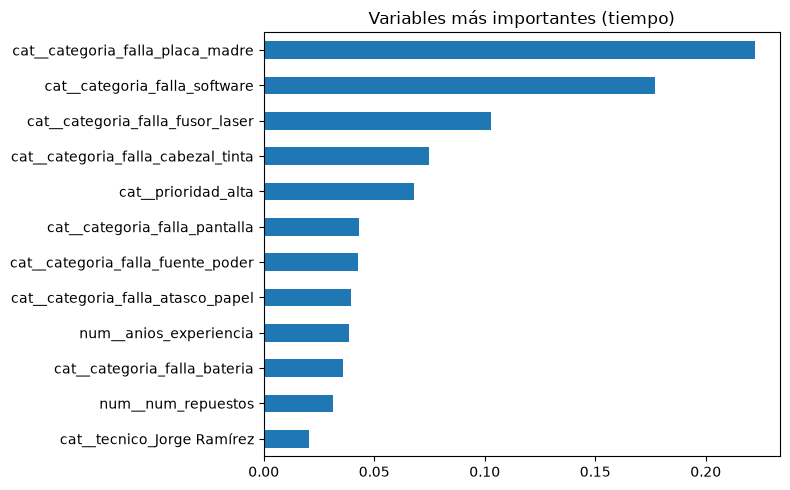

In [8]:
modelo_tiempo = crear_modelo(XGBRegressor(
    n_estimators=150, learning_rate=0.05, max_depth=3,
    min_child_weight=10, subsample=0.8, random_state=42
)).fit(X_train, np.log(yt_train))

nombres = modelo_tiempo.named_steps["prep"].get_feature_names_out()
importancias = modelo_tiempo.named_steps["modelo"].feature_importances_

imp = pd.Series(importancias, index=nombres).sort_values(ascending=True).tail(12)
imp.plot(kind="barh", figsize=(8, 5), title="Variables más importantes (tiempo)")
plt.tight_layout()
plt.show()

In [9]:
import joblib
from pathlib import Path

modelo_costo = crear_modelo(XGBRegressor(
    n_estimators=300, learning_rate=0.05, max_depth=5, random_state=42
)).fit(X_train, yc_train)

carpeta = Path("../models")
joblib.dump(modelo_tiempo, carpeta / "modelo_tiempo.pkl")
joblib.dump(modelo_costo, carpeta / "modelo_costo.pkl")

t = joblib.load(carpeta / "modelo_tiempo.pkl")
c = joblib.load(carpeta / "modelo_costo.pkl")

nueva = pd.DataFrame([{
    "tipo_equipo": "laptop", "marca": "Apple", "categoria_falla": "pantalla",
    "tecnico": "Miguel Salazar", "anios_experiencia": 1,
    "num_repuestos": 2, "prioridad": "alta",
}])

print(f"Tiempo estimado: {np.exp(t.predict(nueva)[0]):.1f} días")
print(f"Costo estimado: S/ {c.predict(nueva)[0]:.0f}")

Tiempo estimado: 5.4 días
Costo estimado: S/ 681
